### Prophet model from facebook to be used in time series analysis

In [13]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [34]:
# import dataset
df = pd.read_csv('/home/talha/Data/AiEngineer/Deep_Learning/01_weather_forecasting_project/DailyClimateTrain.csv', index_col='date', parse_dates=True)
print(df.head())
print(df.tail())
print(df.describe())

             meantemp   humidity  wind_speed  meanpressure
date                                                      
2013-01-01  10.000000  84.500000    0.000000   1015.666667
2013-01-02   7.400000  92.000000    2.980000   1017.800000
2013-01-03   7.166667  87.000000    4.633333   1018.666667
2013-01-04   8.666667  71.333333    1.233333   1017.166667
2013-01-05   6.000000  86.833333    3.700000   1016.500000
             meantemp    humidity  wind_speed  meanpressure
date                                                       
2016-12-28  17.217391   68.043478    3.547826   1015.565217
2016-12-29  15.238095   87.857143    6.000000   1016.904762
2016-12-30  14.095238   89.666667    6.266667   1017.904762
2016-12-31  15.052632   87.000000    7.325000   1016.100000
2017-01-01  10.000000  100.000000    0.000000   1016.000000
          meantemp     humidity   wind_speed  meanpressure
count  1462.000000  1462.000000  1462.000000   1462.000000
mean     25.495521    60.771702     6.802209   10

In [36]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1462 entries, 2013-01-01 to 2017-01-01
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   meantemp      1462 non-null   float64
 1   humidity      1462 non-null   float64
 2   wind_speed    1462 non-null   float64
 3   meanpressure  1462 non-null   float64
dtypes: float64(4)
memory usage: 57.1 KB


<Axes: xlabel='date', ylabel='meantemp'>

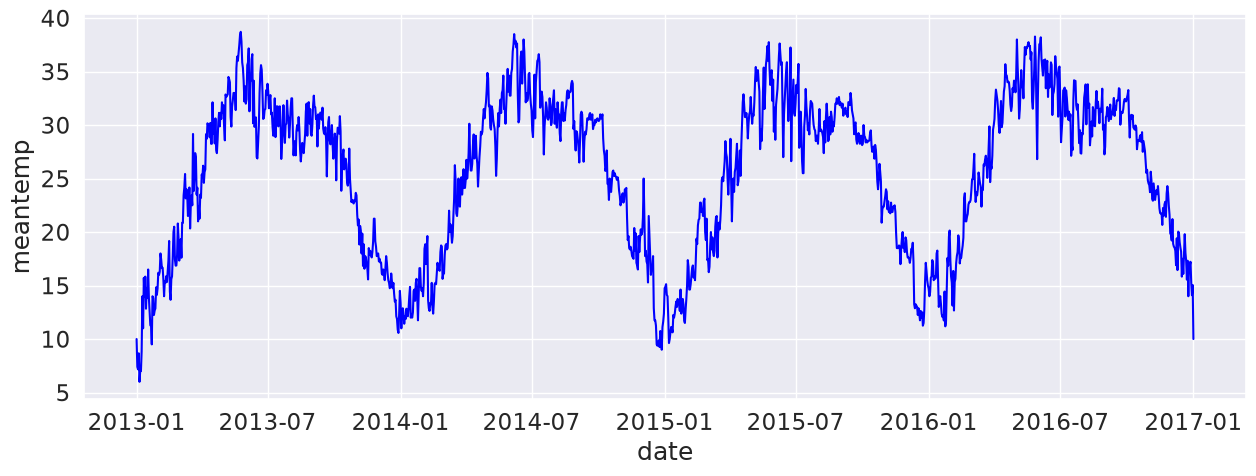

In [4]:
# draw a line plot
sns.set(rc={'figure.figsize':(15, 5)}, font_scale=1.5, style='darkgrid')
sns.lineplot(data=df, x='date', y='meantemp', color='blue')

In [5]:
# draw same plot on plotly  
fig = px.line(df, x=df.index, y='meantemp', title='Mean Temperature Over Time')
fig.show()

In [6]:
# make a scatter plot between meantemp and humidity
fig = px.scatter(df, x='meantemp', y='humidity', title='Mean Temperature vs Humidity')
fig.show()

In [ ]:
from scipy.stats import pearsonr
corr_coef, p_value = pearsonr(df['meantemp'], df['humidity'])
# print the results
print(f"Correlation Coefficient: {corr_coef}")

Correlation Coefficient: -0.5719507155817222


<Axes: >

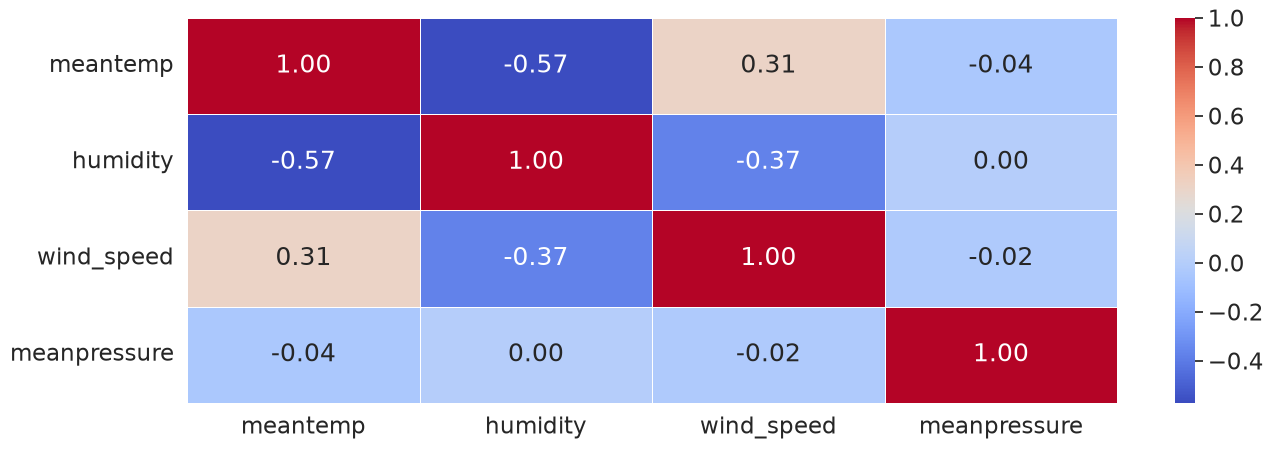

In [11]:
# make a heat map of correlation
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

In [17]:
# lets scale the data
from sklearn.preprocessing import MinMaxScaler, StandardScaler
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns, index=df.index)
df_scaled.describe()

,meantemp,humidity,wind_speed,meanpressure
count,1.462000e+03,1.462000e+03,1.462000e+03,1.462000e+03
mean,4.860073e-18,1.895429e-16,-2.187033e-17,-5.807788e-16
std,1.000342e+00,1.000342e+00,1.000342e+00,1.000342e+00
min,-2.654044e+00,-2.824109e+00,-1.491699e+00,-5.628829e+00
25%,-9.037230e-01,-6.201833e-01,-7.296443e-01,-5.286224e-02
50%,3.020541e-01,1.105528e-01,-1.273107e-01,-1.410365e-02
75%,7.909894e-01,6.828386e-01,5.342114e-01,2.131517e-02
max,1.799551e+00,2.340044e+00,7.766988e+00,3.701076e+01


<Axes: >

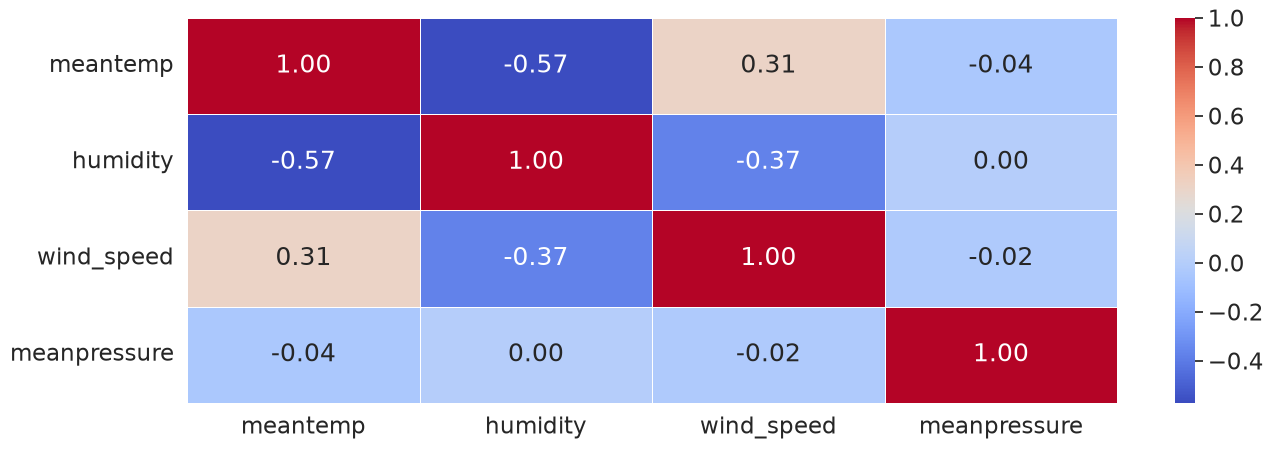

In [18]:
# make a correlation heatmap of scaled data
sns.heatmap(df_scaled.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

In [19]:
# add two columns in the dataset for month and year
df_scaled['month'] = df_scaled.index.month
df_scaled['year'] = df_scaled.index.year
df_scaled.head()

,meantemp,humidity,wind_speed,meanpressure,month,year
date,,,,,,
2013-01-01,-2.109500,1.415439,-1.491699,0.025321,1,2013
2013-01-02,-2.463454,1.862828,-0.838196,0.037162,1,2013
2013-01-03,-2.495219,1.564569,-0.475626,0.041972,1,2013
2013-01-04,-2.291015,0.630022,-1.221233,0.033647,1,2013
2013-01-05,-2.654044,1.554627,-0.680303,0.029946,1,2013


In [20]:
df_scaled.year.unique()

array([2013, 2014, 2015, 2016, 2017], dtype=int32)

<Axes: xlabel='month', ylabel='meantemp'>

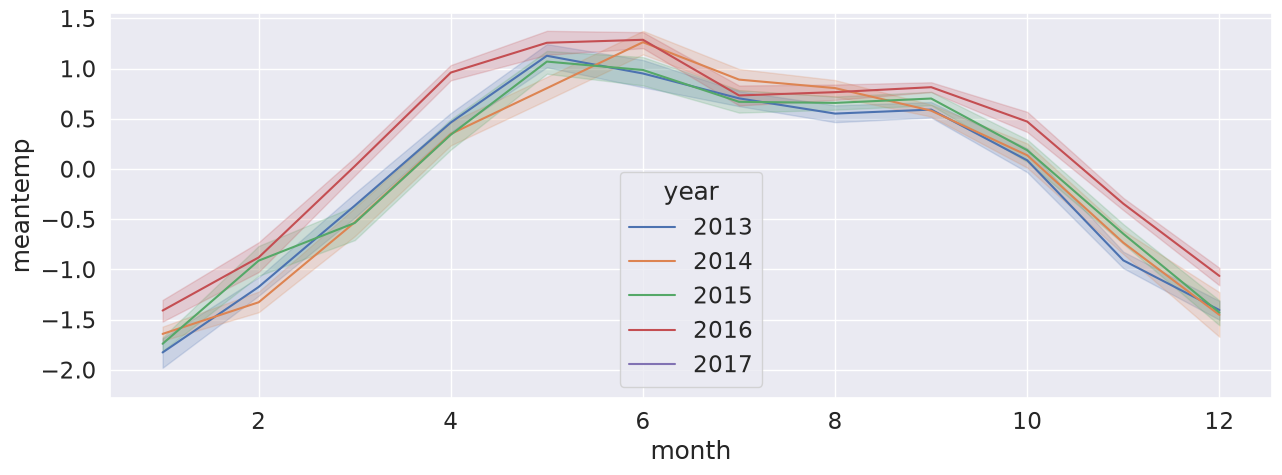

In [22]:
sns.lineplot(data=df_scaled, x='month', y='meantemp', hue='year', palette='deep')

In [29]:
# add two columns in the dataset for month and year
df['month'] = df.index.month
df['year'] = df.index.year
df.head()

,meantemp,humidity,wind_speed,meanpressure,month,year
date,,,,,,
2013-01-01,10.000000,84.500000,0.000000,1015.666667,1,2013
2013-01-02,7.400000,92.000000,2.980000,1017.800000,1,2013
2013-01-03,7.166667,87.000000,4.633333,1018.666667,1,2013
2013-01-04,8.666667,71.333333,1.233333,1017.166667,1,2013
2013-01-05,6.000000,86.833333,3.700000,1016.500000,1,2013


In [32]:
# same in plotly 
fig = px.line(df, x=df.index, y='meantemp', color='year', title='Mean Temperature Over Months for Each Year')
fig.show()

In [46]:
df = df.reset_index()

### lets use the prphet model from python

In [47]:
df = df.rename(columns={'date': 'ds'})
print(df.head())

          ds          y   humidity  wind_speed  meanpressure
0 2013-01-01  10.000000  84.500000    0.000000   1015.666667
1 2013-01-02   7.400000  92.000000    2.980000   1017.800000
2 2013-01-03   7.166667  87.000000    4.633333   1018.666667
3 2013-01-04   8.666667  71.333333    1.233333   1017.166667
4 2013-01-05   6.000000  86.833333    3.700000   1016.500000


17:36:41 - cmdstanpy - INFO - Chain [1] start processing
17:36:41 - cmdstanpy - INFO - Chain [1] done processing


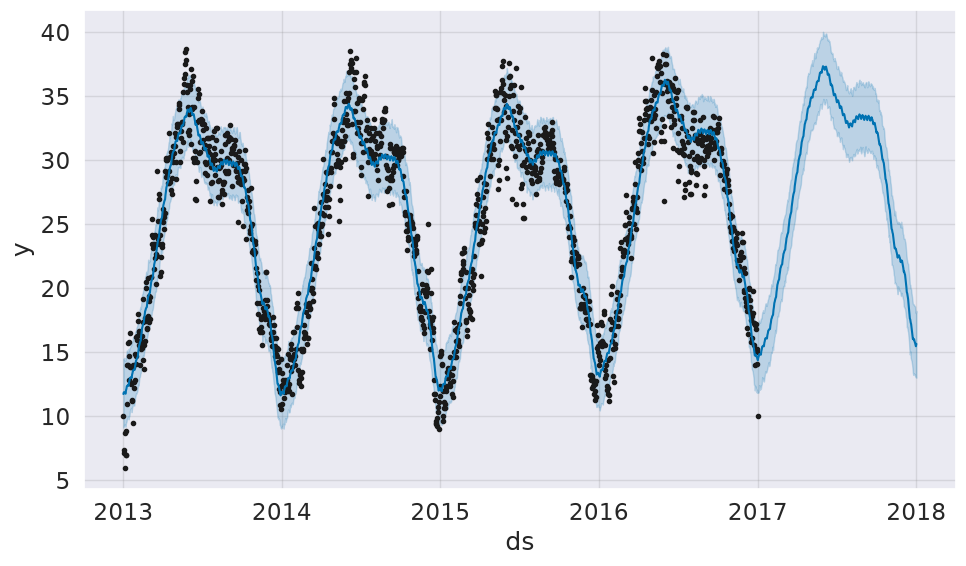

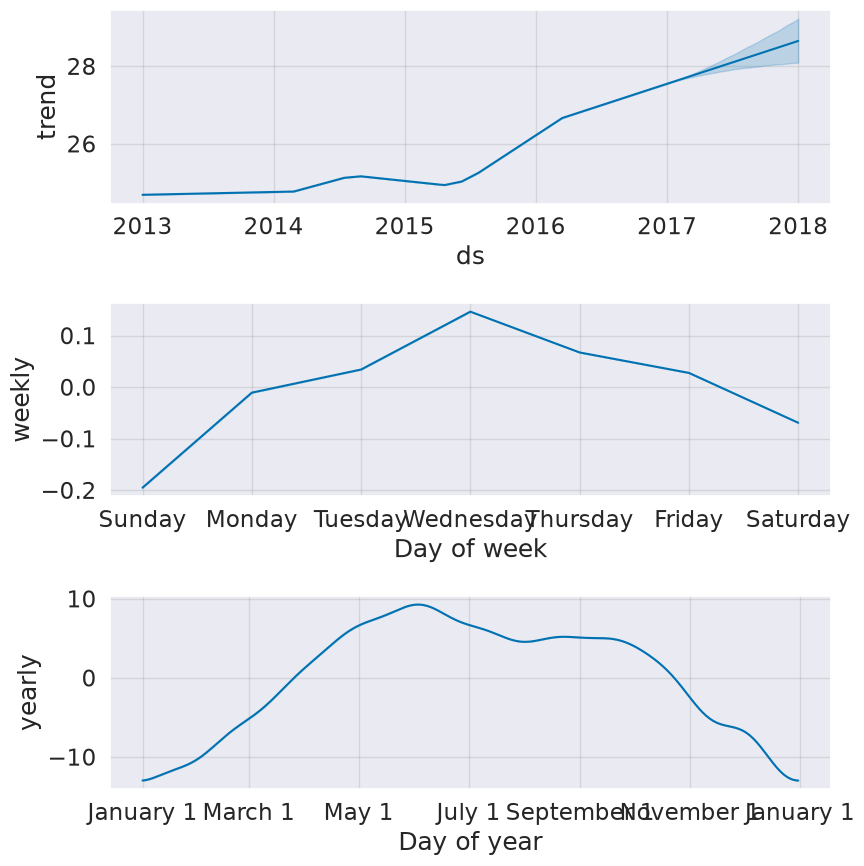

In [53]:
from prophet import Prophet
from prophet.plot import plot_plotly, plot_components_plotly

model = Prophet()
model.fit(df)

forecast = model.make_future_dataframe(periods=365)
prediction = model.predict(forecast)

model.plot(prediction)
plt.show()
model.plot_components(prediction)
plt.show()

In [54]:
forecast.head()

,ds
0,2013-01-01
1,2013-01-02
2,2013-01-03
3,2013-01-04
4,2013-01-05
